
# BMMC consensus trajectory visualization notebook

This notebook redraws the simplified **trajectory comparison (panel C style)** using the results under:

```text
/data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC
```

For each pairing ratio (`pair_000`, `pair_020`, ..., `pair_100`), it generates a **two-panel figure**:

1. **Predicted Trajectory**: UMAP scatter colored by predicted time (0 to 1).
2. **Reference Trajectory**: the same UMAP layout colored by the stage category derived from your `stage_map`.

The figure is intentionally clean and simple, so you can compare it with the earlier version and decide which style is better.


In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm

try:
    from umap import UMAP
    HAS_UMAP = True
except Exception as e:
    print(f"[Warning] umap-learn is unavailable: {e}")
    HAS_UMAP = False
    from sklearn.decomposition import PCA


In [2]:

# =========================
# User configuration
# =========================
ROOT = Path('/data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC')
PAIR_DIRS = ['pair_000', 'pair_020', 'pair_040', 'pair_060', 'pair_080', 'pair_100']
OUT_DIR = ROOT / 'trajectory_visualizations_simple_v2'
OUT_DIR.mkdir(parents=True, exist_ok=True)

STAGE_MAP = {
    'HSC': 0,
    'Lymph prog': 1,
    'G/M prog': 1,
    'MK/E prog': 1,
    'ID2-hi myeloid prog': 1,
    'CD4+ T naive': 2,
    'CD8+ T naive': 2,
    'Naive CD20+ B': 2,
    'Transitional B': 2,
    'B1 B': 2,
    'Proerythroblast': 2,
    'NK': 3,
    'CD8+ T': 3,
    'CD4+ T activated': 3,
    'CD14+ Mono': 3,
    'CD16+ Mono': 3,
    'pDC': 3,
    'cDC2': 3,
    'ILC': 3,
    'Plasma cell': 3,
    'Erythroblast': 3,
    'Normoblast': 4,
}

# blue -> pink for predicted time
TIME_CMAP = LinearSegmentedColormap.from_list(
    'time_blue_pink', ['#6FA8DC', '#F08AC0']
)

# 5 ordered stage-group colors, from light to deep
STAGE_COLORS = ['#D8E8F7', '#B8D0F0', '#D7C1E8', '#EAA0D0', '#D25D9C']
STAGE_CMAP = ListedColormap(STAGE_COLORS)
STAGE_NORM = BoundaryNorm(np.arange(-0.5, 5.5, 1), STAGE_CMAP.N)


In [3]:

# =========================
# Helper functions
# =========================

def load_npz_dict(path: Path):
    with np.load(path, allow_pickle=False) as data:
        return {k: data[k] for k in data.files}


def load_json(path: Path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


def first_existing_key(d, candidates):
    for k in candidates:
        if k in d:
            return k
    return None


def get_embedding_matrix(pred):
    emb_key = first_existing_key(pred, ['h_fused', 'h', 'z', 'latent', 'embedding'])
    if emb_key is not None:
        return pred[emb_key], emb_key

    emb_key = first_existing_key(pred, ['z_atac', 'h_atac', 'atac_latent', 'embed_atac'])
    if emb_key is not None:
        return pred[emb_key], emb_key

    emb_key = first_existing_key(pred, ['true_rna', 'pred_rna'])
    if emb_key is not None:
        warnings.warn(f'Using {emb_key} as layout input because no latent embedding was found.')
        return pred[emb_key], emb_key

    raise KeyError('Could not find a usable embedding matrix in predictions.npz')


def get_time_array(pred):
    key = first_existing_key(pred, ['time', 'time_head', 'pseudotime', 'latent_time'])
    if key is None:
        raise KeyError('Could not find predicted time in predictions.npz')
    return np.asarray(pred[key]).reshape(-1), key


def get_labels_from_npz(pred):
    key = first_existing_key(pred, ['labels', 'label', 'cell_type', 'cell_types'])
    if key is None:
        return None, None
    return pred[key].astype(str), key


def get_labels_from_csv(run_dir: Path):
    csv_path = run_dir / 'T3_stage_reference.csv'
    if not csv_path.exists():
        return None, None
    df = pd.read_csv(csv_path)
    for col in ['label', 'labels', 'cell_type', 'stage_label', 'reference_label']:
        if col in df.columns:
            return df[col].astype(str).to_numpy(), col
    obj_cols = [c for c in df.columns if df[c].dtype == object]
    if len(obj_cols) == 1:
        return df[obj_cols[0]].astype(str).to_numpy(), obj_cols[0]
    return None, None


def labels_to_stage_ids(labels, stage_map):
    return np.array([stage_map.get(str(x), np.nan) for x in labels], dtype=float)


def compute_layout(X, random_state=1234):
    X = np.asarray(X)
    if X.ndim != 2:
        raise ValueError(f'Expected a 2D matrix, got shape={X.shape}')
    if X.shape[1] == 2:
        return X
    if HAS_UMAP:
        reducer = UMAP(n_components=2, n_neighbors=20, min_dist=0.35, metric='euclidean', random_state=random_state)
        return reducer.fit_transform(X)
    print('[Info] Falling back to PCA(2) because UMAP is unavailable.')
    return PCA(n_components=2, random_state=random_state).fit_transform(X)


def inspect_pair(run_dir: Path):
    print(f'\n===== {run_dir.name} =====')
    pred_path = run_dir / 'predictions.npz'
    metrics_path = run_dir / 'metrics.json'
    csv_path = run_dir / 'T3_stage_reference.csv'
    print('predictions.npz:', pred_path.exists())
    print('metrics.json    :', metrics_path.exists())
    print('T3_stage_reference.csv:', csv_path.exists())
    if pred_path.exists():
        pred = load_npz_dict(pred_path)
        for k, v in pred.items():
            print(f'  {k:<18} shape={getattr(v, "shape", None)} dtype={getattr(v, "dtype", None)}')


In [4]:

# Inspect all ratio directories first
for d in PAIR_DIRS:
    inspect_pair(ROOT / d)



===== pair_000 =====
predictions.npz: True
metrics.json    : True
T3_stage_reference.csv: True
  cell_ids           shape=(5161,) dtype=<U25
  z_atac             shape=(5161, 32) dtype=float32
  z_rna              shape=(5161, 32) dtype=float32
  h_fused            shape=(5161, 32) dtype=float32
  pred_rna           shape=(5161, 12093) dtype=float32
  true_rna           shape=(5161, 12093) dtype=float32
  t1_true_pca        shape=(5161, 30) dtype=float64
  t1_pred_pca        shape=(5161, 30) dtype=float64
  time               shape=(5161,) dtype=float32
  time_head          shape=(5161,) dtype=float32
  labels             shape=(5161,) dtype=<U20

===== pair_020 =====
predictions.npz: True
metrics.json    : True
T3_stage_reference.csv: True
  cell_ids           shape=(6191,) dtype=<U25
  z_atac             shape=(6191, 32) dtype=float32
  z_rna              shape=(6191, 32) dtype=float32
  h_fused            shape=(6191, 32) dtype=float32
  pred_rna           shape=(6191, 12093) dtype

In [5]:

# =========================
# Core plotting function
# =========================

def plot_simple_t3_panel(run_dir: Path, save=True, show=True):
    pred_path = run_dir / 'predictions.npz'
    metrics_path = run_dir / 'metrics.json'

    pred = load_npz_dict(pred_path)
    metrics = load_json(metrics_path) if metrics_path.exists() else {}

    X, emb_key = get_embedding_matrix(pred)
    time, time_key = get_time_array(pred)

    labels, label_key = get_labels_from_npz(pred)
    if labels is None:
        labels, label_key = get_labels_from_csv(run_dir)
    if labels is None:
        raise ValueError(f'No labels found in {run_dir}. Please inspect predictions.npz or T3_stage_reference.csv')

    if len(time) != X.shape[0]:
        raise ValueError(f'Time length {len(time)} does not match embedding rows {X.shape[0]}')
    if len(labels) != X.shape[0]:
        raise ValueError(f'Label length {len(labels)} does not match embedding rows {X.shape[0]}')

    stage_ids = labels_to_stage_ids(labels, STAGE_MAP)
    valid = np.isfinite(stage_ids)
    layout = compute_layout(X, random_state=1234)

    fig, axes = plt.subplots(2, 1, figsize=(5.4, 8.8))
    ax1, ax2 = axes

    # top: predicted time
    sc1 = ax1.scatter(layout[:, 0], layout[:, 1], c=time, cmap=TIME_CMAP, s=6, alpha=0.85, linewidths=0)
    cb1 = plt.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)
    cb1.set_label('Predicted time', fontsize=10)
    cb1.set_ticks([0.0, 1.0])
    ax1.set_title('Predicted Trajectory', fontsize=20, pad=10)
    ax1.set_xlabel('UMAP 1', fontsize=12)
    ax1.set_ylabel('UMAP 2', fontsize=12)
    ax1.spines[['top', 'right']].set_visible(False)
    ax1.set_xticks([])
    ax1.set_yticks([])

    # bottom: reference stages
    sc2 = ax2.scatter(layout[valid, 0], layout[valid, 1], c=stage_ids[valid], cmap=STAGE_CMAP, norm=STAGE_NORM, s=6, alpha=0.85, linewidths=0)
    cb2 = plt.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
    cb2.set_label('Stage group', fontsize=10)
    cb2.set_ticks([0, 1, 2, 3, 4])
    ax2.set_title('Reference Trajectory', fontsize=20, pad=10)
    ax2.set_xlabel('UMAP 1', fontsize=12)
    ax2.set_ylabel('UMAP 2', fontsize=12)
    ax2.spines[['top', 'right']].set_visible(False)
    ax2.set_xticks([])
    ax2.set_yticks([])

    poa = metrics.get('T3', {}).get('POA', None)
    poauc = metrics.get('T3', {}).get('POAUC', None)
    title = f'BMMC {run_dir.name} (consensus)'
    if poa is not None and poauc is not None:
        title += f' | POA={poa*100:.1f}, POAUC={poauc*100:.1f}'
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.995)

    fig.text(0.5, 0.005, f'UMAP from {emb_key}; predicted time from {time_key}; labels from {label_key}', ha='center', va='bottom', fontsize=8, color='gray')
    plt.tight_layout(rect=[0, 0.02, 1, 0.98])

    if save:
        out_png = OUT_DIR / f'{run_dir.name}_trajectory_simple_v2.png'
        out_pdf = OUT_DIR / f'{run_dir.name}_trajectory_simple_v2.pdf'
        fig.savefig(out_png, dpi=300, bbox_inches='tight')
        fig.savefig(out_pdf, bbox_inches='tight')
        print('Saved:', out_png)
        print('Saved:', out_pdf)

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        'run_dir': str(run_dir),
        'embedding_key': emb_key,
        'time_key': time_key,
        'label_key': label_key,
        'n_cells': int(X.shape[0]),
        'n_valid_stage_labels': int(valid.sum()),
    }


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_020_trajectory_simple_v2.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_020_trajectory_simple_v2.pdf


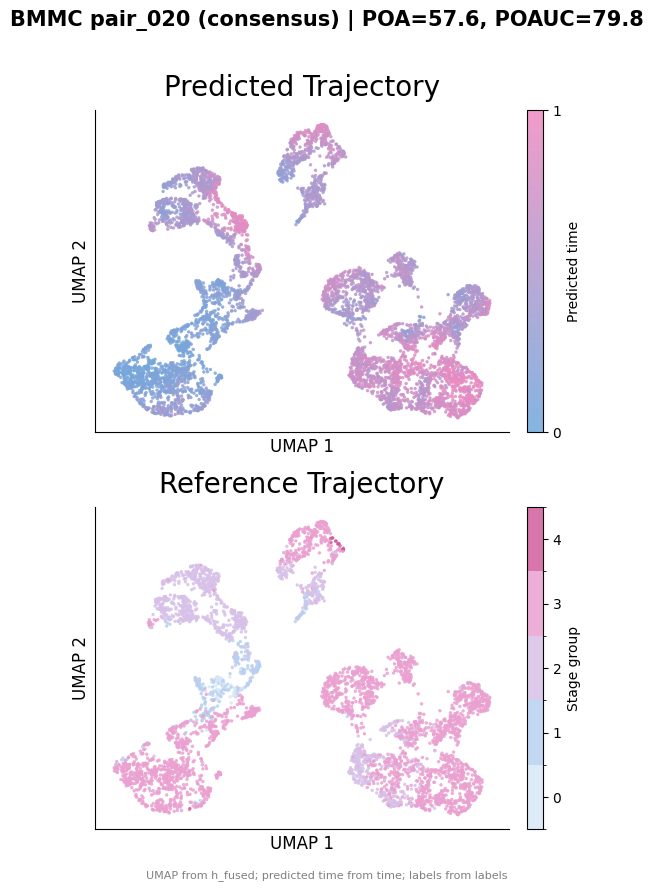

{'run_dir': '/data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020',
 'embedding_key': 'h_fused',
 'time_key': 'time',
 'label_key': 'labels',
 'n_cells': 6191,
 'n_valid_stage_labels': 4333}

In [6]:

# Test one ratio first
info = plot_simple_t3_panel(ROOT / 'pair_020', save=True, show=True)
info


In [7]:

# Batch-generate all ratios
summary = []
for d in PAIR_DIRS:
    info = plot_simple_t3_panel(ROOT / d, save=True, show=False)
    summary.append(info)

summary_df = pd.DataFrame(summary)
summary_df


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_000_trajectory_simple_v2.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_000_trajectory_simple_v2.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_020_trajectory_simple_v2.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_020_trajectory_simple_v2.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


...

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_080_trajectory_simple_v2.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_080_trajectory_simple_v2.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_100_trajectory_simple_v2.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/pair_100_trajectory_simple_v2.pdf


,run_dir,embedding_key,time_key,label_key,n_cells,n_valid_stage_labels
0,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,5161,3613
1,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,6191,4333
2,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,7174,5021
3,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,8211,5748
4,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,9319,6524
5,/data5/zhangye/ATLAS/results/t3_early_stop/BMM...,h_fused,time,labels,10315,7222


In [8]:

summary_df.to_csv(OUT_DIR / 'trajectory_visualization_summary_v2.csv', index=False)
print('Saved:', OUT_DIR / 'trajectory_visualization_summary_v2.csv')
print('All figures saved to:', OUT_DIR)


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2/trajectory_visualization_summary_v2.csv
All figures saved to: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/trajectory_visualizations_simple_v2



## Notes

1. This notebook reads from the **consensus** results under `BMMC_full_01/consensus/seed_1234/BMMC`.
2. The top panel is colored by predicted continuous time (0 to 1).
3. The bottom panel is colored by the **5 reference stage groups** defined by your `stage_map`.
4. If labels are not inside `predictions.npz`, the notebook falls back to `T3_stage_reference.csv`.
5. If `umap-learn` is unavailable, the layout falls back to PCA(2), but UMAP is preferred.
